In [9]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

DATA_PATH = Path('../data/spotify-2023-cleaned.csv')
MODEL_DIR = Path('../models')
MODEL_DIR.mkdir(exist_ok=True)
target = 'streams'

df = pd.read_csv(DATA_PATH)
print(df.head())
print(f"\nLoaded shape: {df.shape}")

                            track_name    artist(s)_name  artist_count  \
0  Seven (feat. Latto) (Explicit Ver.)  Latto, Jung Kook             2   
1                                 LALA       Myke Towers             1   
2                              vampire    Olivia Rodrigo             1   
3                         Cruel Summer      Taylor Swift             1   
4                       WHERE SHE GOES         Bad Bunny             1   

   released_year  released_month  released_day  in_spotify_playlists  \
0           2023               7            14                   553   
1           2023               3            23                  1474   
2           2023               6            30                  1397   
3           2019               8            23                  7858   
4           2023               5            18                  3133   

   in_spotify_charts      streams  in_apple_playlists  ...  bpm  key   mode  \
0                147  141381703.0          

In [ ]:
def train_and_evaluate(feature_vector, target='streams'):
    X = df[feature_vector].copy()
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # n_estimators: The number of trees in the forest. A higher number can improve performance but increases computation time.
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)

    y_pred = rf_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return rf_model, {
        'features': feature_vector,
        'mse': mse,
        'rmse': rmse,
        'r2': r2,
    }

In [ ]:
def train_and_evaluate(feature_vector, target='streams'):
    X = df[feature_vector].copy()
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    xgb_model = XGBRegressor(
        n_estimators=100,  # Number of trees
        learning_rate=0.1,  # Step size shrinkage
        max_depth=6,  # Maximum depth of a tree
        random_state=42
    )
    xgb_model.fit(X_train, y_train)

    y_pred = xgb_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return xgb_model, {
        'features': feature_vector,
        'mse': mse,
        'rmse': rmse,
        'r2': r2,
    }

In [3]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

print("\nCorrelation of features with 'streams':")
print(corr[target].sort_values(ascending=False))


Correlation of features with 'streams':
streams                 1.000000
in_spotify_playlists    0.789786
in_apple_playlists      0.771917
in_deezer_playlists     0.516312
in_apple_charts         0.320057
in_spotify_charts       0.245773
in_deezer_charts        0.228575
in_shazam_charts        0.050578
released_day            0.010587
bpm                    -0.002438
acousticness_%         -0.004483
released_month         -0.024912
energy_%               -0.026050
valence_%              -0.040810
instrumentalness_%     -0.044902
liveness_%             -0.048337
danceability_%         -0.105406
speechiness_%          -0.112302
artist_count           -0.136436
released_year          -0.228506
Name: streams, dtype: float64


In [13]:
low_corr_features = corr[corr[target].abs() < 0.05].index.tolist()
high_corr_features = low_corr_features.drop([target], axis=1).columns.tolist()
print("\nFeatures with correlation >= 0.05 with 'streams':")
print(high_corr_features)

AttributeError: 'list' object has no attribute 'drop'

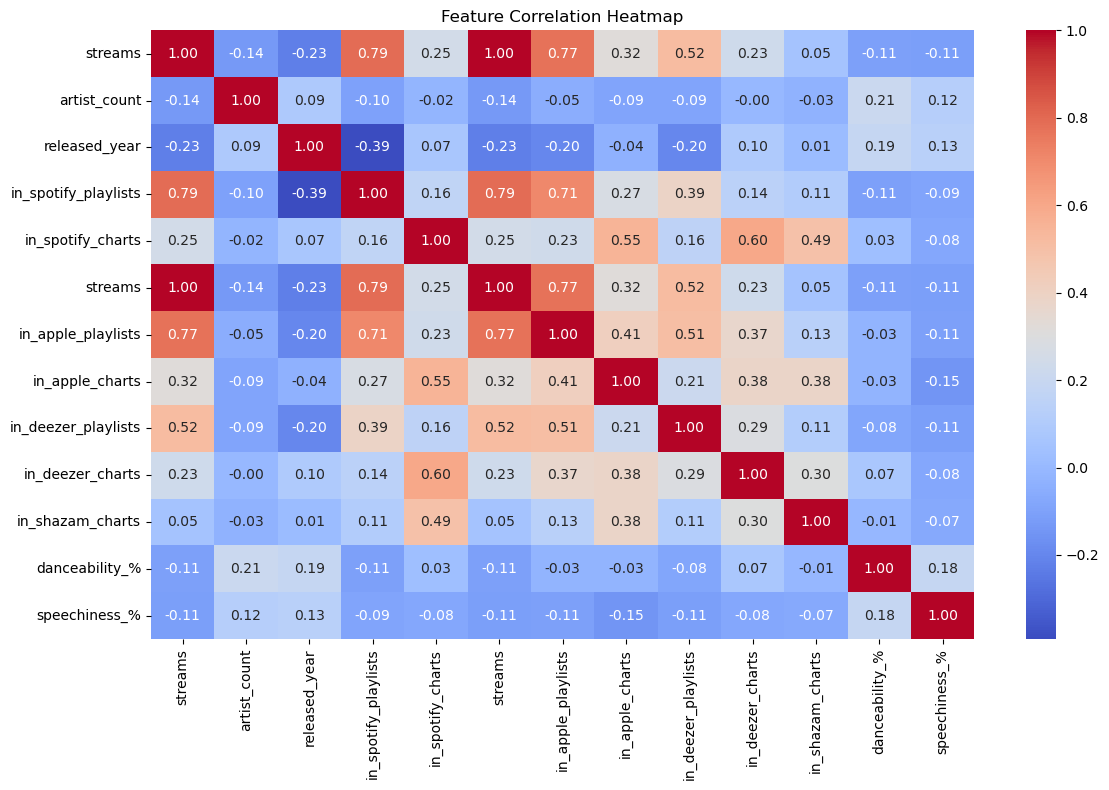

In [11]:

# Heatmap for the high correlation features
feature_subset = ['streams'] + high_corr_features
feature_subset = [col for col in feature_subset if col in df.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(df[feature_subset].corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


In [ ]:
results = {
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],

    "RMSE": [
        lr_rmse,
        rf_rmse,
        xgb_rmse
    ],

    "R2": [
        lr_r2,
        rf_r2,
        xgb_r2
    ]
}

import pandas as pd

pd.DataFrame(results)